In [16]:
import pandas as pd
import numpy as np

df_base = pd.read_csv('data/processed_data_base1.csv')
df = pd.read_csv('data/processed_data1.csv')

In [17]:
df_base.head()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed
0,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,False,False,True,False,False,False,True,False,False,False
1,57,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,False,False,True,False,False,False,True,False,False,False
2,37,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,False,False,True,False,False,False,True,False,False,False
3,40,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,False,False,True,False,False,False,True,False,False,False
4,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,False,False,True,False,False,False,True,False,False,False


In [18]:
df.head()

,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,default_unknown,default_yes,...,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,pre_contact,age_group_26-35,age_group_36-45,age_group_46-55,age_group_56-65,age_group_65+
0,0.693147,0.0,1.1,93.994,-36.4,4.857,5191.0,0,False,False,...,True,False,False,False,0,False,False,False,True,False
1,0.693147,0.0,1.1,93.994,-36.4,4.857,5191.0,0,True,False,...,True,False,False,False,0,False,False,False,True,False
2,0.693147,0.0,1.1,93.994,-36.4,4.857,5191.0,0,False,False,...,True,False,False,False,0,False,True,False,False,False
3,0.693147,0.0,1.1,93.994,-36.4,4.857,5191.0,0,False,False,...,True,False,False,False,0,False,True,False,False,False
4,0.693147,0.0,1.1,93.994,-36.4,4.857,5191.0,0,False,False,...,True,False,False,False,0,False,False,False,True,False


In [19]:
df.columns

Index(['campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'default_unknown',
       'default_yes', 'housing_unknown', 'housing_yes', 'loan_unknown',
       'loan_yes', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid',
       'job_management', 'job_retired', 'job_self-employed', 'job_services',
       'job_student', 'job_technician', 'job_unemployed', 'job_unknown',
       'marital_married', 'marital_single', 'marital_unknown',
       'education_basic.6y', 'education_basic.9y', 'education_high.school',
       'education_illiterate', 'education_professional.course',
       'education_university.degree', 'education_unknown',
       'poutcome_nonexistent', 'poutcome_success', 'contact_telephone',
       'month_aug', 'month_dec', 'month_jul', 'month_jun', 'month_mar',
       'month_may', 'month_nov', 'month_oct', 'month_sep', 'day_of_week_mon',
       'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'pre_contact',

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 57 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   campaign                       41188 non-null  float64
 1   previous                       41188 non-null  float64
 2   emp.var.rate                   41188 non-null  float64
 3   cons.price.idx                 41188 non-null  float64
 4   cons.conf.idx                  41188 non-null  float64
 5   euribor3m                      41188 non-null  float64
 6   nr.employed                    41188 non-null  float64
 7   y                              41188 non-null  int64  
 8   default_unknown                41188 non-null  bool   
 9   default_yes                    41188 non-null  bool   
 10  housing_unknown                41188 non-null  bool   
 11  housing_yes                    41188 non-null  bool   
 12  loan_unknown                   41188 non-null  bool   
 1

In [21]:
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_recall_curve,
    classification_report,
    precision_recall_fscore_support,
    average_precision_score)

import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 交叉验证的评估指标
cv_scoring = {'Accuracy': 'accuracy', 'F1': 'f1', 'PR-AUC': 'average_precision'}


def add_comprehensive_metrics(result, y_true, y_pred, y_prob):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0
    )
    negative_pr_auc = average_precision_score(1 - np.asarray(y_true), 1 - y_prob)
    positive_pr_auc = average_precision_score(y_true, y_prob)
    result.update({
        'Precision-负类': precision[0],
        'Recall-负类': recall[0],
        'F1-负类': f1[0],
        'Precision-正类': precision[1],
        'Recall-正类': recall[1],
        'F1-正类': f1[1],
        'Precision-macro': precision.mean(),
        'Recall-macro': recall.mean(),
        'F1-macro': f1.mean(),
        'Precision-weighted': np.average(precision, weights=support),
        'Recall-weighted': np.average(recall, weights=support),
        'F1-weighted': np.average(f1, weights=support),
        'PR-AUC-负类': negative_pr_auc,
        'PR-AUC-正类': positive_pr_auc,
        'PR-AUC-weighted': np.average(
            [negative_pr_auc, positive_pr_auc],
            weights=support
        )
    })
    return result

# 1. baseline

In [22]:
# 基线模型：原始特征 + 逻辑回归
X_base = df_base.drop(['y'], axis=1)
y_base = df_base['y']

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(X_base, y_base, test_size=0.2, stratify=y_base, random_state=42)

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        # tol=1e-4,
        class_weight='balanced',
        random_state=42)
    )
baseline_cv = cross_validate(
    baseline_model, X_train_base, y_train_base,
    cv=5, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)

baseline_model.fit(X_train_base, y_train_base)
y_base_prob = baseline_model.predict_proba(X_test_base)[:, 1]
y_base_pred = baseline_model.predict(X_test_base)

baseline_results = {
    '模型': '基线-逻辑回归',
    'Accuracy': accuracy_score(y_test_base, y_base_pred),
    'F1': f1_score(y_test_base, y_base_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test_base, y_base_prob),
    'CV Accuracy均值': baseline_cv['test_Accuracy'].mean(),
    'CV F1均值': baseline_cv['test_F1'].mean(),
    'CV PR-AUC均值': baseline_cv['test_PR-AUC'].mean()
}

test_probabilities = {'基线-逻辑回归': (y_test_base, y_base_prob)}
model_results = [baseline_results]
fitted_models = {}

print(classification_report(
    y_test_base,
    y_base_pred,
    target_names=['负类 0', '正类 1'],
    zero_division=0
))

              precision    recall  f1-score   support

        负类 0       0.95      0.86      0.90      7310
        正类 1       0.37      0.64      0.47       928

    accuracy                           0.83      8238
   macro avg       0.66      0.75      0.68      8238
weighted avg       0.88      0.83      0.85      8238



# 2. 特征工程

In [23]:
X = df.drop(['y'], axis=1)
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 类别不平衡处理
positive_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

In [24]:
# 逻辑回归
lr_cv = cross_validate(
    baseline_model, X_train, y_train,
    cv=5, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)

baseline_model.fit(X_train, y_train)
lr_prob = baseline_model.predict_proba(X_test)[:, 1]
lr_pred = baseline_model.predict(X_test)

lr_result = {
    '模型': '逻辑回归',
    'Accuracy': accuracy_score(y_test, lr_pred),
    'F1': f1_score(y_test, lr_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, lr_prob),
    'CV F1均值': lr_cv['test_F1'].mean(),
    'CV PR-AUC均值': lr_cv['test_PR-AUC'].mean()
}

test_probabilities['逻辑回归'] = (y_test, lr_prob)
model_results.append(lr_result)
fitted_models['逻辑回归'] = baseline_model

print('逻辑回归分类报告')
print(classification_report(
    y_test,
    lr_pred,
    target_names=['负类 0', '正类 1'],
    zero_division=0
))

逻辑回归分类报告
              precision    recall  f1-score   support

        负类 0       0.95      0.86      0.90      7310
        正类 1       0.37      0.65      0.47       928

    accuracy                           0.83      8238
   macro avg       0.66      0.75      0.68      8238
weighted avg       0.88      0.83      0.85      8238



In [25]:
# XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=positive_weight,
    random_state=42,
    eval_metric='logloss',
    n_jobs=1
)
xgb_cv = cross_validate(
    xgb_model, X_train, y_train,
    cv=5, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = xgb_model.predict(X_test)

xgb_result = {
    '模型': 'XGBoost',
    'Accuracy': accuracy_score(y_test, xgb_pred),
    'F1': f1_score(y_test, xgb_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, xgb_prob),
    'CV F1均值': xgb_cv['test_F1'].mean(),
    'CV PR-AUC均值': xgb_cv['test_PR-AUC'].mean()
}

test_probabilities['XGBoost'] = (y_test, xgb_prob)
model_results.append(xgb_result)
fitted_models['XGBoost'] = xgb_model

print('XGBoost分类报告')
print(classification_report(
    y_test,
    xgb_pred,
    target_names=['负类 0', '正类 1'],
    zero_division=0
))

XGBoost分类报告
              precision    recall  f1-score   support

        负类 0       0.95      0.87      0.91      7310
        正类 1       0.39      0.65      0.49       928

    accuracy                           0.85      8238
   macro avg       0.67      0.76      0.70      8238
weighted avg       0.89      0.85      0.86      8238



In [26]:
# LightGBM：按类别比例提高正类权重，并限制最大 boosting 轮数
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    scale_pos_weight=positive_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1,
    n_jobs=1
)
lgbm_cv = cross_validate(
    lgbm_model, X_train, y_train,
    cv=5, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)

lgbm_model.fit(X_train, y_train)
lgbm_prob = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_pred = lgbm_model.predict(X_test)

lgbm_result = {
    '模型': 'LightGBM',
    'Accuracy': accuracy_score(y_test, lgbm_pred),
    'F1': f1_score(y_test, lgbm_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, lgbm_prob),
    'CV F1均值': lgbm_cv['test_F1'].mean(),
    'CV PR-AUC均值': lgbm_cv['test_PR-AUC'].mean()
}

test_probabilities['LightGBM'] = (y_test, lgbm_prob)
model_results.append(lgbm_result)
fitted_models['LightGBM'] = lgbm_model

print('LightGBM分类报告')
print(classification_report(
    y_test,
    lgbm_pred,
    target_names=['负类 0', '正类 1'],
    zero_division=0
))

LightGBM分类报告
              precision    recall  f1-score   support

        负类 0       0.95      0.88      0.91      7310
        正类 1       0.41      0.66      0.50       928

    accuracy                           0.85      8238
   macro avg       0.68      0.77      0.71      8238
weighted avg       0.89      0.85      0.87      8238



# 3. 模型效果对比

         模型  Accuracy  Precision-负类  Recall-负类   F1-负类  Precision-正类  \
0  LightGBM    0.8541        0.9527     0.8792  0.9145        0.4082   
1   XGBoost    0.8460        0.9514     0.8709  0.9094        0.3898   
2      逻辑回归    0.8342        0.9504     0.8579  0.9018        0.3665   
3   基线-逻辑回归    0.8348        0.9501     0.8590  0.9022        0.3671   

   Recall-正类   F1-正类  Precision-weighted  Recall-weighted  F1-weighted  
0     0.6562  0.5033              0.8914           0.8541       0.8682  
1     0.6498  0.4873              0.8882           0.8460       0.8618  
2     0.6476  0.4681              0.8847           0.8342       0.8529  
3     0.6444  0.4677              0.8844           0.8348       0.8533  


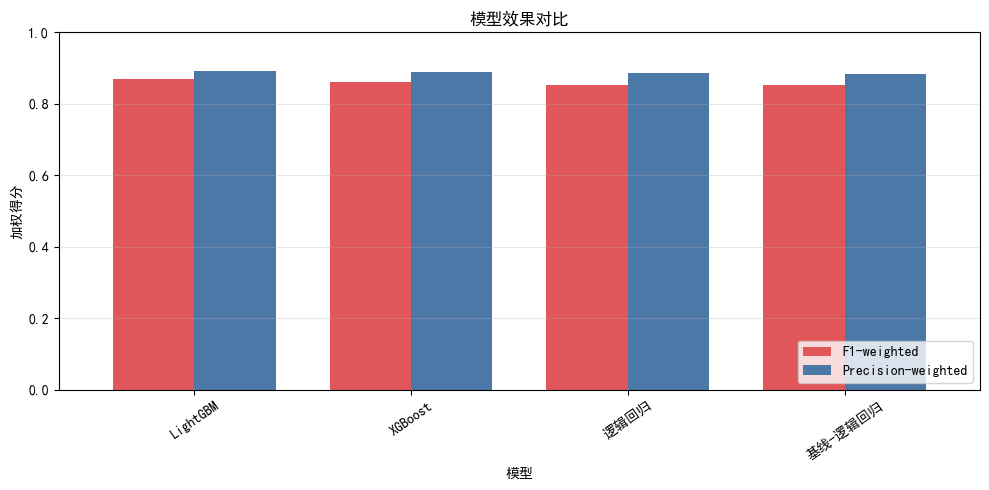

In [27]:
prediction_sets = {
    '基线-逻辑回归': (y_test_base, y_base_pred, y_base_prob),
    '逻辑回归': (y_test, lr_pred, lr_prob),
    'XGBoost': (y_test, xgb_pred, xgb_prob),
    'LightGBM': (y_test, lgbm_pred, lgbm_prob)
}

for result in model_results:
    y_true_model, y_pred_model, y_prob_model = prediction_sets[result['模型']]
    add_comprehensive_metrics(
        result,
        y_true_model,
        y_pred_model,
        y_prob_model
    )

comparison_df = (
    pd.DataFrame(model_results)
    .sort_values(by='F1-正类', ascending=False)
    .reset_index(drop=True)
)

comparison_columns = [
    '模型',
    'Accuracy',
    'Precision-负类',
    'Recall-负类',
    'F1-负类',
    'Precision-正类',
    'Recall-正类',
    'F1-正类',
    'Precision-weighted',
    'Recall-weighted',
    'F1-weighted'
]
print(comparison_df[comparison_columns].round(4))

focus_metrics = ['F1-weighted', 'Precision-weighted']
comparison_df.set_index('模型')[focus_metrics].plot(
    kind='bar',
    figsize=(10, 5),
    ylim=(0, 1),
    rot=35,
    width=0.75,
    color=['#E15759', '#4C78A8']
)

plt.title('模型效果对比')
plt.ylabel('加权得分')
plt.xlabel('模型')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 4. LightGBM超参数优化

In [28]:
k_fold = 5

lgbm_search_model = LGBMClassifier(
    objective='binary',
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

random_param_dist = {
    'n_estimators': [400, 600, 800, 1200],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'num_leaves': [7, 15, 31, 63],
    'max_depth': [-1, 4, 6, 8],
    'min_child_samples': [20, 40, 80, 120],
    'subsample': [0.70, 0.85, 1.00],
    'subsample_freq': [1],
    'colsample_bytree': [0.70, 0.85, 1.00],
    'reg_alpha': [0.0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.0, 1.0, 5.0, 10.0],
    'scale_pos_weight': [
        positive_weight * 0.25,
        positive_weight * 0.50,
        positive_weight * 0.75,
        positive_weight
    ]
}

random_search = RandomizedSearchCV(
    estimator=lgbm_search_model,
    param_distributions=random_param_dist,
    n_iter=50,
    scoring='f1',
    cv=k_fold,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)
random_search.fit(X_train, y_train)

best_tuned_estimator = random_search.best_estimator_
print('F1 最优参数：')
print(random_search.best_params_)
print(f'交叉验证 F1：{random_search.best_score_:.4f}')

F1 最优参数：
{'subsample_freq': 1, 'subsample': 1.0, 'scale_pos_weight': np.float64(3.9383081896551726), 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'num_leaves': 7, 'n_estimators': 1200, 'min_child_samples': 40, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 0.85}
交叉验证 F1：0.4993


In [29]:
threshold_grid = np.arange(0.10, 0.91, 0.01)
oof_prob = cross_val_predict(
    best_tuned_estimator,
    X_train,
    y_train,
    cv=k_fold,
    method='predict_proba',
    n_jobs=-1
)[:, 1]
oof_f1_scores = [
    f1_score(y_train, (oof_prob >= threshold).astype(int), zero_division=0)
    for threshold in threshold_grid
]
best_threshold = threshold_grid[int(np.argmax(oof_f1_scores))]

optimized_cv = cross_validate(
    best_tuned_estimator,
    X_train,
    y_train,
    cv=k_fold,
    scoring={'F1': 'f1', 'PR-AUC': 'average_precision'},
    n_jobs=-1,
    return_train_score=False
)

best_tuned_estimator.fit(X_train, y_train)
tuned_prob = best_tuned_estimator.predict_proba(X_test)[:, 1]
tuned_pred_default = (tuned_prob >= 0.5).astype(int)
tuned_pred = (tuned_prob >= best_threshold).astype(int)

tuned_results = {
    '模型': 'LightGBM-最终优化',
    'Threshold': best_threshold,
    'Accuracy': accuracy_score(y_test, tuned_pred),
    'F1': f1_score(y_test, tuned_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, tuned_prob),
    'CV F1均值': optimized_cv['test_F1'].mean(),
    'CV PR-AUC均值': optimized_cv['test_PR-AUC'].mean(),
    '默认阈值F1': f1_score(y_test, tuned_pred_default, zero_division=0)
}
add_comprehensive_metrics(tuned_results, y_test, tuned_pred, tuned_prob)

original_lgbm_metrics = next(
    result for result in model_results if result['模型'] == 'LightGBM'
)
add_comprehensive_metrics(
    original_lgbm_metrics,
    y_test,
    lgbm_pred,
    lgbm_prob
)
tuning_comparison = pd.DataFrame([
    {
        '模型': 'LightGBM-原始',
        'Threshold': 0.5,
        'Accuracy': original_lgbm_metrics['Accuracy'],
        'F1-负类': original_lgbm_metrics['F1-负类'],
        'F1-正类': original_lgbm_metrics['F1-正类'],
        'F1-weighted': original_lgbm_metrics['F1-weighted'],
        'PR-AUC-负类': original_lgbm_metrics['PR-AUC-负类'],
        'PR-AUC-正类': original_lgbm_metrics['PR-AUC-正类'],
        'PR-AUC-weighted': original_lgbm_metrics['PR-AUC-weighted']
    },
    {key: tuned_results[key] for key in [
        '模型', 'Threshold', 'Accuracy', 'F1-负类', 'F1-正类',
        'F1-weighted', 'PR-AUC-负类', 'PR-AUC-正类', 'PR-AUC-weighted'
    ]}
])

test_probabilities['LightGBM-最终优化'] = (y_test, tuned_prob)
fitted_models['LightGBM-最终优化'] = best_tuned_estimator

print('LightGBM-最终优化分类报告')
print(classification_report(
    y_test,
    tuned_pred,
    target_names=['负类 0', '正类 1'],
    zero_division=0
))

LightGBM-最终优化分类报告
              precision    recall  f1-score   support

        负类 0       0.95      0.92      0.93      7310
        正类 1       0.48      0.60      0.53       928

    accuracy                           0.88      8238
   macro avg       0.71      0.76      0.73      8238
weighted avg       0.89      0.88      0.89      8238



In [30]:
tuning_comparison.round(4)

,模型,Threshold,Accuracy,F1-负类,F1-正类,F1-weighted,PR-AUC-负类,PR-AUC-正类,PR-AUC-weighted
0,LightGBM-原始,0.5,0.8541,0.9145,0.5033,0.8682,0.9607,0.4955,0.9083
1,LightGBM-最终优化,0.5,0.8823,0.9326,0.5328,0.8876,0.9600,0.4878,0.9068
